# King County House Sales: Price Analysis and Prediction

## Objective

This project analyses house sales in King County (Seattle area) and builds regression models to predict sale prices from features such as square footage, number of bedrooms and number of floors. It was completed as the final project of the “Data Analysis with Python” course (IBM, Coursera).

## About the Dataset

This [dataset](https://www.kaggle.com/harlfoxem/housesalesprediction) contains house sale prices for King County, which includes Seattle. It includes homes sold between May 2014 and May 2015. It was also slightly modified for the purposes of this course.

| Variable      | Description                                                                                                 |
| ------------- | ----------------------------------------------------------------------------------------------------------- |
| id            | A notation for a house                                                                                      |
| date          | Date house was sold                                                                                         |
| price         | Price is prediction target                                                                                  |
| bedrooms      | Number of bedrooms                                                                                          |
| bathrooms     | Number of bathrooms                                                                                         |
| sqft_living   | Square footage of the home                                                                                  |
| sqft_lot      | Square footage of the lot                                                                                   |
| floors        | Total floors (levels) in house                                                                              |
| waterfront    | House which has a view to a waterfront                                                                      |
| view          | Has been viewed                                                                                             |
| condition     | How good the condition is overall                                                                           |
| grade         | overall grade given to the housing unit, based on King County grading system                                |
| sqft_above    | Square footage of house apart from basement                                                                 |
| sqft_basement | Square footage of the basement                                                                              |
| yr_built      | Built Year                                                                                                  |
| yr_renovated  | Year when house was renovated                                                                               |
| zipcode       | Zip code                                                                                                    |
| lat           | Latitude coordinate                                                                                         |
| long          | Longitude coordinate                                                                                        |
| sqft_living15 | Living room area in 2015(implies-- some renovations) This might or might not have affected the lotsize area |
| sqft_lot15    | LotSize area in 2015(implies-- some renovations)                                                            |


## **Import the required libraries**


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import train_test_split

## Data loading

In [2]:
filepath='https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-SkillsNetwork/labs/FinalModule_Coursera/data/kc_house_data_NaN.csv'

Load the csv:


In [3]:
df = pd.read_csv(filepath)

We use the method <code>head</code> to display the first 5 rows of the dataframe.


In [4]:
df.head()

,Unnamed: 0,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,0,7129300520,20141013T000000,221900.0,3.0,1.00,1180,5650,1.0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,1,6414100192,20141209T000000,538000.0,3.0,2.25,2570,7242,2.0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,2,5631500400,20150225T000000,180000.0,2.0,1.00,770,10000,1.0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,3,2487200875,20141209T000000,604000.0,4.0,3.00,1960,5000,1.0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,4,1954400510,20150218T000000,510000.0,3.0,2.00,1680,8080,1.0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


Display the data types of each column

In [5]:
df.dtypes

Unnamed: 0         int64
id                 int64
date                 str
price            float64
bedrooms         float64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object

Display a statistical summary of the dataframe.


In [6]:
df.describe()

,Unnamed: 0,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,21613.00000,2.161300e+04,2.161300e+04,21600.000000,21603.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,...,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,10806.00000,4.580302e+09,5.400881e+05,3.372870,2.115736,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,...,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,6239.28002,2.876566e+09,3.671272e+05,0.926657,0.768996,918.440897,4.142051e+04,0.539989,0.086517,0.766318,...,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,0.00000,1.000102e+06,7.500000e+04,1.000000,0.500000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,...,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,5403.00000,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,...,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,10806.00000,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,...,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,16209.00000,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,...,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,21612.00000,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,...,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


We observe a possible data error in the `bedrooms` column: the maximum value is **33 bedrooms**, while 75% of the houses have 4 bedrooms or fewer. This value is likely a typo and could be checked (e.g. against its `sqft_living`) or removed in a further analysis.

## Data cleaning

Drop the columns <code>"id"</code>  and <code>"Unnamed: 0"</code> from axis 1, then obtain a statistical summary of the data.


In [7]:
df = df.drop(['id','Unnamed: 0'], axis=1)
df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,21600.000000,21603.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,5.400881e+05,3.372870,2.115736,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,3.671272e+05,0.926657,0.768996,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,7.500000e+04,1.000000,0.500000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


We can see we have missing values for the columns <code> bedrooms</code>  and <code> bathrooms </code>


In [8]:
print("number of NaN values for the column bedrooms :", df['bedrooms'].isnull().sum())
print("number of NaN values for the column bathrooms :", df['bathrooms'].isnull().sum())


number of NaN values for the column bedrooms : 13
number of NaN values for the column bathrooms : 10


We can replace the missing values of the column <code>'bedrooms'</code> with the mean of the column <code>'bedrooms'</code> using the method <code>replace()</code>, assigning the result back to the column.


In [9]:
mean = df['bedrooms'].mean()
df['bedrooms'] = df['bedrooms'].replace(np.nan, mean)

We also replace the missing values of the column <code>'bathrooms'</code> with the mean of the column <code>'bathrooms'</code> using the method <code>replace()</code>, assigning the result back to the column.


In [10]:
mean = df['bathrooms'].mean()
df['bathrooms'] = df['bathrooms'].replace(np.nan, mean)

In [11]:
print("number of NaN values for the column bedrooms :", df['bedrooms'].isnull().sum())
print("number of NaN values for the column bathrooms :", df['bathrooms'].isnull().sum())

number of NaN values for the column bedrooms : 0
number of NaN values for the column bathrooms : 0


There were only **23 missing values** (13 in `bedrooms` and 10 in `bathrooms`), a very small number compared with the 21,613 rows in the dataset. Since both columns are numerical, replacing the missing values with the column mean is a reasonable choice that keeps all the rows. However, both variables are discrete, so the mean introduces non-integer values (e.g. 3.37 bedrooms); the median would have been an alternative that avoids this.

## Exploratory Analysis

Count the number of houses with unique floor values and convert it to a data frame.

In [12]:
floor_values = df['floors'].value_counts().to_frame()
print(floor_values)

        count
floors       
1.0     10680
2.0      8241
1.5      1910
3.0       613
2.5       161
3.5         8


Houses with 1 floor (≈49%) and 2 floors (≈38%) make up the vast majority of the dataset, followed by 1.5 floors (≈9%). Houses with 2.5 floors or more account for only about 3.6% of the sales, and there are just 8 houses with 3.5 floors, so conclusions about these groups should be drawn with caution.

Use a <code>boxplot</code> to  determine whether houses with a waterfront view or without a waterfront view have more price outliers.

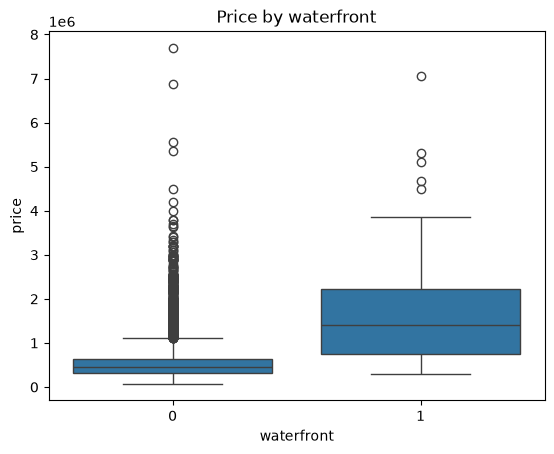

In [13]:
sns.boxplot(x='waterfront', y='price', data=df)
plt.title('Price by waterfront')
plt.show()

The median price is higher for waterfront houses. However, non-waterfront houses have many more price outliers. This is partly explained by group size: only about 0.75% of the houses (≈160) have a waterfront view, so the non-waterfront group is much larger and covers a wider range of properties.

Use a <code>regplot</code> to determine if the feature <code>sqft_above</code> is negatively or positively correlated with price.

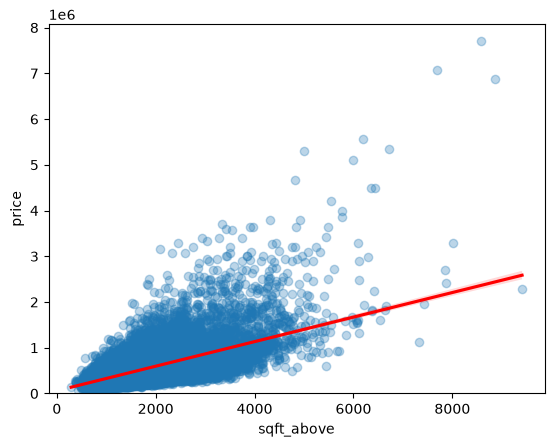

In [14]:
sns.regplot(x='sqft_above', y='price', data=df, line_kws={'color':'red'}, scatter_kws={'alpha':0.3})
plt.ylim(0,)
plt.show()

`sqft_above` is positively correlated with price: larger houses tend to be more expensive. The points also spread out more around the regression line as `sqft_above` increases, which means that square footage alone predicts the price less reliably for larger houses, where other factors (location, grade, views) play a bigger role.

We can use the Pandas method <code>corr()</code> to find the feature other than price that is most correlated with price.

In [15]:
df_numeric = df.select_dtypes(include=[np.number])
df_numeric.corr()['price'].sort_values()

zipcode         -0.053203
long             0.021626
condition        0.036362
yr_built         0.054012
sqft_lot15       0.082447
sqft_lot         0.089661
yr_renovated     0.126434
floors           0.256794
waterfront       0.266369
lat              0.307003
bedrooms         0.308797
sqft_basement    0.323816
view             0.397293
bathrooms        0.525738
sqft_living15    0.585379
sqft_above       0.605567
grade            0.667434
sqft_living      0.702035
price            1.000000
Name: price, dtype: float64

The variables most correlated with price are `sqft_living` (0.70), `grade` (0.67) and `sqft_above` (0.61). The least correlated are `long` (0.02), `condition` (0.04) and `zipcode` (−0.05), all very close to 0. Note that `zipcode` is a code rather than a quantity, so its linear correlation with price is not very meaningful; its effect on price would be better captured by treating it as a categorical variable.

## Modelling

We can fit a linear regression model using the  longitude feature <code>'long'</code> and  calculate the R^2.


In [16]:
X = df[['long']]
Y = df['price']
lm = LinearRegression()
lm.fit(X,Y)
lm.score(X, Y)

0.0004676943014898516

Now we can fit a linear regression model to predict the <code>'price'</code> using the feature <code>'sqft_living'</code>, then calculate the R^2.

In [17]:
X = df[['sqft_living']]
Y = df['price']
lm = LinearRegression()
lm.fit(X,Y)
lm.score(X,Y)

0.4928532179037931

We can also fit a linear regression model to predict the <code>'price'</code> using some of the features together (11). First, we create the list of features:

In [18]:
features =["floors", "waterfront","lat" ,"bedrooms" ,"sqft_basement" ,"view" ,"bathrooms","sqft_living15","sqft_above","grade","sqft_living"]     

Then calculate the R^2.

In [19]:
Y = df['price']
Z = df[features]
lm = LinearRegression()
lm.fit(Z,Y)
lm.score(Z,Y)

0.6576951666037499

We define the pipeline steps by creating a tuple: scaling, second-order polynomial features and linear regression.

<code>'scale'</code>

<code>'polynomial'</code>

<code>'model'</code>

The second element in the tuple  contains the model constructor

<code>StandardScaler()</code>

<code>PolynomialFeatures(include_bias=False)</code>

<code>LinearRegression()</code>

In [20]:
Input=[('scale',StandardScaler()),('polynomial', PolynomialFeatures(include_bias=False)),('model',LinearRegression())]

We can use a pipeline object to predict the 'price', fit the object using the features in the list <code>features</code>, and calculate the R^2.

In [21]:
pipe = Pipeline(Input)
X = df[features]
Y = df['price']
pipe.fit(X,Y)
pipe.score(X,Y)

0.7513408515988733

## Model Evaluation

We will split the data into training and testing sets:


In [22]:
X = df[features]
Y = df['price']

x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.15, random_state=1)


print("number of test samples:", x_test.shape[0])
print("number of training samples:",x_train.shape[0])

number of test samples: 3242
number of training samples: 18371


Then, we create and fit a Ridge regression object using the training data, set the regularization parameter to 0.1, and calculate the R^2 using the test data.

In [23]:
RidgeModel = Ridge(alpha=0.1)
RidgeModel.fit(x_train, y_train)
RidgeModel.score(x_test,y_test)

0.6478759163939114

Now, we perform a second order polynomial transform on both the training data and testing data. Then, create and fit a Ridge regression object using the training data, set the regularisation parameter to 0.1, and calculate the R^2 utilising the test data provided.

In [24]:
pr = PolynomialFeatures(degree=2)
x_train_pr = pr.fit_transform(x_train)
x_test_pr = pr.transform(x_test)

RidgeModel = Ridge(alpha=0.1)
RidgeModel.fit(x_train_pr, y_train)
RidgeModel.score(x_test_pr, y_test)

0.700274425758048

## Conclusions

### Model comparison

| Model | Features | Evaluated on | R² |
|---|---|---|---|
| Simple linear regression | `long` | Full dataset (in-sample) | 0.000 |
| Simple linear regression | `sqft_living` | Full dataset (in-sample) | 0.493 |
| Multiple linear regression | 11 features | Full dataset (in-sample) | 0.658 |
| Pipeline: scaling + polynomial (degree 2) + linear regression | 11 features | Full dataset (in-sample) | 0.751 |
| Ridge regression (α = 0.1) | 11 features | Test set (15%) | 0.648 |
| Ridge regression (α = 0.1) + polynomial (degree 2) | 11 features | Test set (15%) | 0.700 |

### Discussion

- **One variable is not enough.** Longitude alone explains practically none of the variation in price (R² ≈ 0), while `sqft_living`, the variable most correlated with price, explains about 49%.
- **More features and non-linear terms help.** Using the 11 selected features raises R² to 0.658, and adding second-order polynomial terms raises it to 0.751.
- **In-sample and test R² are not directly comparable.** The first four models were fitted and evaluated on the same data, so their R² is optimistic: it measures how well the model fits data it has already seen. The polynomial pipeline uses 77 terms, which increases the risk of overfitting. The two Ridge models were trained on 85% of the data and evaluated on the remaining 15%, which gives a fairer estimate of how they would perform on new houses.
- **Selected model.** Comparing the two models evaluated on the test set, the **second-order polynomial Ridge regression** performs best (R² = 0.700 vs 0.648): it explains about 70% of the variation in price on houses it has not seen.

### Possible improvements

- Review or remove anomalous values, such as the house with 33 bedrooms.
- Tune the regularisation parameter α and the polynomial degree with `GridSearchCV`, instead of fixing α = 0.1.
- Use cross-validation (`cross_val_score`) instead of a single train/test split, to get a more stable estimate of performance.
- Include location more effectively, for example by treating `zipcode` as a categorical variable.
- Report an error metric in dollars (e.g. RMSE) in addition to R², which is easier to interpret from a business perspective.